In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier

In [2]:
class Contextual_Bandit_generator:

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        """
        Initialization of the Contextual Bandit environment.

        It uses sklearn's make_classification to generate a population of config['n_samples'] 
        synthetic (context, best_article) pairs. The 5 generated features serve as the context
        with their corresponding class labels to represent which of the 5 articles is the best 
        recommendation. 
        params: 
            config - dict; sets how many pairs to generate
        
        vars:

            state - history of the entire session. This includes every action taken, context seen,
                    and every reward received. 

            population - generated pairs the environment draws from each time step() is called.

            current_context - holds only the most recent context and its true best article. The 
                                agent reads this to decide its action.
        """
        self.state = {'X':[],'article':[],'reward':[]}
        self.population = [[],[]]
        self.population[0], self.population[1] = make_classification(
            n_samples=config['n_samples'],
            n_features=5,
            n_informative=5,
            n_classes=5,
            n_redundant=0,
            n_repeated=0,
            flip_y=0.2,
            shift = [10,4,0,0,0],
            scale = [7,1,1,1,1],
            random_state=8
        )
        self.population[0] = self.feature_engineer(self.population[0])
        self.current_context = {'X':[],'best_article':[]}
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def feature_engineer(self, Data):
        """
        Reshapes the generated features to realistic data to match the example feature table. 
        It is also called only one for the whole population, only interacting with the features.

        params: 
            Data - data that is going to be feature engineered

        returns: the data, but now modified
        """
        Data[:,0] = (Data[:,0]>0)*1
        Data[:,1] = (Data[:,1]>0)*1
        Data[:,3][(Data[:,3]<0)] = 0
        Data[:,3][(Data[:,3]>5)] = 5
        Data[:,3] = np.round(Data[:,3])
        Data[:,4] = np.round(Data[:,4])
        return Data

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def step(self):
        """
        Model takes a step (action) through the environment, where then an article is chosen at random.
        The current_context variable is then updated with the choice and the best_article with it. 
        """
        sample = np.random.choice(len(self.population[1]))
        x = self.population[0][sample]
        ba = self.population[1][sample]
        if len(self.state['X']) == 0:
            self.state['X'] = x
        else:
            self.state['X'] = np.vstack((self.state['X'],x))
        self.current_context['X'] = x
        self.current_context['best_article'] = ba

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reward(self,a):        
        """
        Grants the agent a reward based on the article that was chosen. 

        If the agent's choice matches the best article, then reward is 1 with a probability of 0.9. 
        Otherwise, reward is 1 with probability of 0.05.  
        
        params: 
            a - article that was chosen by the agent
        """
        if self.current_context['best_article'] == a:
            response = np.random.binomial(n = 1, p = 0.9,size = 1)[0]
        else:
            response = np.random.binomial(n = 1, p = 0.05,size = 1)[0]
        if len(self.state['X']) == 0:      
            self.state['article'] = np.array(a)
            self.state['reward'] = np.array(response)
        else:
            self.state['article'] = np.append(self.state['article'],a)
            self.state['reward'] = np.append(self.state['reward'],response)
        

# 2 - Learn about the environment

In [3]:
#intended setup
env_config = {'n_samples':100000}
env = Contextual_Bandit_generator(env_config)


In [4]:
#intended use, a = 10
env.step()
a = 10
env.reward(a)
env.state


{'X': array([ 1.        ,  1.        ,  4.26526526,  0.        , 79.        ]),
 'article': array([10.]),
 'reward': array([0.])}

In [5]:
#intended use, a = 100
env.step()
a = 100
env.reward(a)
env.state


{'X': array([[ 1.        ,  1.        ,  4.26526526,  0.        , 79.        ],
        [ 0.        ,  0.        ,  3.09805222,  1.        , 79.        ]]),
 'article': array([ 10., 100.]),
 'reward': array([0., 0.])}

In [6]:
#intended use, a = 1000
env.step()
a = 1000
env.reward(a)
env.state


{'X': array([[ 1.        ,  1.        ,  4.26526526,  0.        , 79.        ],
        [ 0.        ,  0.        ,  3.09805222,  1.        , 79.        ],
        [ 0.        ,  0.        ,  7.84734413,  2.        , 59.        ]]),
 'article': array([  10.,  100., 1000.]),
 'reward': array([0., 0., 0.])}

In [7]:
#intended use, a = 10000
env.step()
a = 10000
env.reward(a)
env.state


{'X': array([[ 1.        ,  1.        ,  4.26526526,  0.        , 79.        ],
        [ 0.        ,  0.        ,  3.09805222,  1.        , 79.        ],
        [ 0.        ,  0.        ,  7.84734413,  2.        , 59.        ],
        [ 1.        ,  0.        ,  6.46885444,  0.        , 56.        ]]),
 'article': array([   10.,   100.,  1000., 10000.]),
 'reward': array([0., 0., 0., 0.])}

In [8]:
#intended use, a = 100000
env.step()
a = 100000
env.reward(a)
env.state

{'X': array([[ 1.        ,  1.        ,  4.26526526,  0.        , 79.        ],
        [ 0.        ,  0.        ,  3.09805222,  1.        , 79.        ],
        [ 0.        ,  0.        ,  7.84734413,  2.        , 59.        ],
        [ 1.        ,  0.        ,  6.46885444,  0.        , 56.        ],
        [ 1.        ,  0.        ,  2.13634885,  0.        , 77.        ]]),
 'article': array([1.e+01, 1.e+02, 1.e+03, 1.e+04, 1.e+05]),
 'reward': array([0., 0., 0., 0., 0.])}

# 3 - Implement a simple Contextual Bandit

In [14]:
Ts = [100, 250, 500]
bs = [100, 1000]
es = [0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]

A = [0, 1, 2, 3, 4]

results = []
results_broken = []

In [ ]:
for T in Ts:
    for b in bs:
        for e in es:

            env_config = {'n_samples':100000}
            env = Contextual_Bandit_generator(env_config)

            models = {}
            fitted = {}

            for a in A:
                models[a] = RandomForestClassifier()
                fitted[a] = False

            rewards = []

            for t in range(1, 5001):
                env.step()
                X = env.current_context['X']

                if t <= T:
                    a = np.random.choice(A)
                else:
                    if np.random.random() < e or not all(fitted.values()):
                        a = np.random.choice(A)
                    else:
                        predictions = []
                        for a2 in A:
                            prediction = models[a2].predict_proba([X])[0][1]
                            predictions.append(prediction)

                        a = A[np.argmax(predictions)]

                env.reward(a)
                rewards.append(env.state['reward'][-1])

                if t % b == 0:
                    X_data = np.array(env.state['X'])
                    article_data = np.array(env.state['article'])
                    reward_data = np.array(env.state['reward'])

                    for a in A:
                        mask = article_data == a

                        X_a = X_data[mask]
                        y_a = reward_data[mask]

                        if len(X_a) > 0 and len(np.unique(y_a)) == 2:
                            models[a].fit(X_a, y_a)
                            fitted[a] = True

            average_reward = np.mean(rewards)
            results.append({
                'T': T,
                'b': b,
                'e':e,
                'average_reward': average_reward
            })

            print(
                f"T={T}, b={b}, e={e}",
                f"average reward = {average_reward:.4f}"
            )

T=100, b=100, e=0 average reward = 0.4664
T=100, b=100, e=0.05 average reward = 0.4770
T=100, b=100, e=0.1 average reward = 0.4430
T=100, b=100, e=0.2 average reward = 0.4042
T=100, b=100, e=0.3 average reward = 0.3898
T=100, b=100, e=0.4 average reward = 0.3564
T=100, b=100, e=0.5 average reward = 0.3348
T=100, b=1000, e=0 average reward = 0.4224
T=100, b=1000, e=0.05 average reward = 0.4106
T=100, b=1000, e=0.1 average reward = 0.4072
T=100, b=1000, e=0.2 average reward = 0.3750
T=100, b=1000, e=0.3 average reward = 0.3672
T=100, b=1000, e=0.4 average reward = 0.3446
T=100, b=1000, e=0.5 average reward = 0.3306
T=250, b=100, e=0 average reward = 0.4764
T=250, b=100, e=0.05 average reward = 0.4402
T=250, b=100, e=0.1 average reward = 0.4462
T=250, b=100, e=0.2 average reward = 0.4056
T=250, b=100, e=0.3 average reward = 0.3924
T=250, b=100, e=0.4 average reward = 0.3620
T=250, b=100, e=0.5 average reward = 0.3442
T=250, b=1000, e=0 average reward = 0.4288
T=250, b=1000, e=0.05 average

## Values from intial run
T=100, b=100, e=0 average reward = 0.4664  
T=100, b=100, e=0.05 average reward = 0.4770  
T=100, b=100, e=0.1 average reward = 0.4430  
T=100, b=100, e=0.2 average reward = 0.4042  
T=100, b=100, e=0.3 average reward = 0.3898  
T=100, b=100, e=0.4 average reward = 0.3564  
T=100, b=100, e=0.5 average reward = 0.3348  
T=100, b=1000, e=0 average reward = 0.4224  
T=100, b=1000, e=0.05 average reward = 0.4106  
T=100, b=1000, e=0.1 average reward = 0.4072  
T=100, b=1000, e=0.2 average reward = 0.3750  
T=100, b=1000, e=0.3 average reward = 0.3672  
T=100, b=1000, e=0.4 average reward = 0.3446  
T=100, b=1000, e=0.5 average reward = 0.3306  
T=250, b=100, e=0 average reward = 0.4764  
T=250, b=100, e=0.05 average reward = 0.4402  
T=250, b=100, e=0.1 average reward = 0.4462  
T=250, b=100, e=0.2 average reward = 0.4056  
T=250, b=100, e=0.3 average reward = 0.3924  
T=250, b=100, e=0.4 average reward = 0.3620  
T=250, b=100, e=0.5 average reward = 0.3442  
T=250, b=1000, e=0 average reward = 0.4288  
T=250, b=1000, e=0.05 average reward = 0.4220  
T=250, b=1000, e=0.1 average reward = 0.4054  
T=250, b=1000, e=0.2 average reward = 0.3652  
T=250, b=1000, e=0.3 average reward = 0.3680  
T=250, b=1000, e=0.4 average reward = 0.3438  
T=250, b=1000, e=0.5 average reward = 0.3288  
T=500, b=100, e=0 average reward = 0.4672  
T=500, b=100, e=0.05 average reward = 0.4430  
T=500, b=100, e=0.1 average reward = 0.4330  
T=500, b=100, e=0.2 average reward = 0.4264  
T=500, b=100, e=0.3 average reward = 0.3870  
T=500, b=100, e=0.4 average reward = 0.3576  
T=500, b=100, e=0.5 average reward = 0.3446  
T=500, b=1000, e=0 average reward = 0.4082  
T=500, b=1000, e=0.05 average reward = 0.4206  
T=500, b=1000, e=0.1 average reward = 0.4052  
T=500, b=1000, e=0.2 average reward = 0.3814  
T=500, b=1000, e=0.3 average reward = 0.3466  
T=500, b=1000, e=0.4 average reward = 0.3510  
T=500, b=1000, e=0.5 average reward = 0.3120  

# 4 - Break Something!

In [16]:
# After a certain point, the Contextual Bandit's information will be mapped differently
class NonstationaryBanditGenerator(Contextual_Bandit_generator):
    def __init__(self, config, switch_at=2500):
        super().__init__(config)
        self.switch_at = switch_at
        self.t = 0
        self.remap = {0:2, 1:3, 2:4, 3:0, 4:1}

    def step(self):
        super().step()
        self.t += 1
        if self.t > self.switch_at:
            old = self.current_context['best_article']
            self.current_context['best_article'] = self.remap[old]

In [20]:
for T in Ts:
    for b in bs:
        for e in es:

            env_config = {'n_samples':100000}
            env = NonstationaryBanditGenerator(env_config)

            models = {}
            fitted = {}

            for a in A:
                models[a] = RandomForestClassifier()
                fitted[a] = False

            rewards = []

            for t in range(1, 5001):
                env.step()
                X = env.current_context['X']

                if t <= T:
                    a = np.random.choice(A)
                else:
                    if np.random.random() < e or not all(fitted.values()):
                        a = np.random.choice(A)
                    else:
                        predictions = []
                        for a2 in A:
                            prediction = models[a2].predict_proba([X])[0][1]
                            predictions.append(prediction)

                        a = A[np.argmax(predictions)]

                env.reward(a)
                rewards.append(env.state['reward'][-1])

                if t % b == 0:
                    X_data = np.array(env.state['X'])
                    article_data = np.array(env.state['article'])
                    reward_data = np.array(env.state['reward'])

                    for a in A:
                        mask = article_data == a

                        X_a = X_data[mask]
                        y_a = reward_data[mask]

                        if len(X_a) > 0 and len(np.unique(y_a)) == 2:
                            models[a].fit(X_a, y_a)
                            fitted[a] = True

            average_reward = np.mean(rewards)
            results_broken.append({
                'T': T,
                'b': b,
                'e':e,
                'average_reward': average_reward
            })

            print(
                f"T={T}, b={b}, e={e}",
                f"average reward = {average_reward:.4f}"
            )

T=100, b=100, e=0 average reward = 0.3082
T=100, b=100, e=0.05 average reward = 0.3128
T=100, b=100, e=0.1 average reward = 0.3176
T=100, b=100, e=0.2 average reward = 0.3094
T=100, b=100, e=0.3 average reward = 0.3074
T=100, b=100, e=0.4 average reward = 0.2818
T=100, b=100, e=0.5 average reward = 0.2694
T=100, b=1000, e=0 average reward = 0.2868
T=100, b=1000, e=0.05 average reward = 0.2610
T=100, b=1000, e=0.1 average reward = 0.2760
T=100, b=1000, e=0.2 average reward = 0.2600
T=100, b=1000, e=0.3 average reward = 0.2714
T=100, b=1000, e=0.4 average reward = 0.2550
T=100, b=1000, e=0.5 average reward = 0.2448
T=250, b=100, e=0 average reward = 0.3264
T=250, b=100, e=0.05 average reward = 0.3292
T=250, b=100, e=0.1 average reward = 0.3256
T=250, b=100, e=0.2 average reward = 0.2930
T=250, b=100, e=0.3 average reward = 0.2888
T=250, b=100, e=0.4 average reward = 0.2876
T=250, b=100, e=0.5 average reward = 0.2700
T=250, b=1000, e=0 average reward = 0.2614
T=250, b=1000, e=0.05 average

## Results from non-stationary
T=100, b=100, e=0 average reward = 0.3082  
T=100, b=100, e=0.05 average reward = 0.3128  
T=100, b=100, e=0.1 average reward = 0.3176  
T=100, b=100, e=0.2 average reward = 0.3094  
T=100, b=100, e=0.3 average reward = 0.3074  
T=100, b=100, e=0.4 average reward = 0.2818  
T=100, b=100, e=0.5 average reward = 0.2694  
T=100, b=1000, e=0 average reward = 0.2868  
T=100, b=1000, e=0.05 average reward = 0.2610  
T=100, b=1000, e=0.1 average reward = 0.2760  
T=100, b=1000, e=0.2 average reward = 0.2600  
T=100, b=1000, e=0.3 average reward = 0.2714  
T=100, b=1000, e=0.4 average reward = 0.2550  
T=100, b=1000, e=0.5 average reward = 0.2448  
T=250, b=100, e=0 average reward = 0.3264  
T=250, b=100, e=0.05 average reward = 0.3292  
T=250, b=100, e=0.1 average reward = 0.3256  
T=250, b=100, e=0.2 average reward = 0.2930  
T=250, b=100, e=0.3 average reward = 0.2888  
T=250, b=100, e=0.4 average reward = 0.2876  
T=250, b=100, e=0.5 average reward = 0.2700  
T=250, b=1000, e=0 average reward = 0.2614  
T=250, b=1000, e=0.05 average reward = 0.2632  
T=250, b=1000, e=0.1 average reward = 0.2702  
T=250, b=1000, e=0.2 average reward = 0.2798  
T=250, b=1000, e=0.3 average reward = 0.2686  
T=250, b=1000, e=0.4 average reward = 0.2730  
T=250, b=1000, e=0.5 average reward = 0.2564  
T=500, b=100, e=0 average reward = 0.3210  
T=500, b=100, e=0.05 average reward = 0.3134  
T=500, b=100, e=0.1 average reward = 0.3180  
T=500, b=100, e=0.2 average reward = 0.2982  
T=500, b=100, e=0.3 average reward = 0.2936  
T=500, b=100, e=0.4 average reward = 0.2788  
T=500, b=100, e=0.5 average reward = 0.2724  
T=500, b=1000, e=0 average reward = 0.2766  
T=500, b=1000, e=0.05 average reward = 0.2864  
T=500, b=1000, e=0.1 average reward = 0.2660  
T=500, b=1000, e=0.2 average reward = 0.2748  
T=500, b=1000, e=0.3 average reward = 0.2616  
T=500, b=1000, e=0.4 average reward = 0.2502  
T=500, b=1000, e=0.5 average reward = 0.2542  

In [21]:
# fixed 
window = 1000  # only use the most recent `window` samples per action when refitting

results_fixed = []

for T in Ts:
    for b in bs:
        for e in es:

            env_config = {'n_samples':100000}
            env = NonstationaryBanditGenerator(env_config)

            models = {}
            fitted = {}

            for a in A:
                models[a] = RandomForestClassifier()
                fitted[a] = False

            rewards = []

            for t in range(1, 5001):
                env.step()
                X = env.current_context['X']

                if t <= T:
                    a = np.random.choice(A)
                else:
                    if np.random.random() < e or not all(fitted.values()):
                        a = np.random.choice(A)
                    else:
                        predictions = []
                        for a2 in A:
                            prediction = models[a2].predict_proba([X])[0][1]
                            predictions.append(prediction)

                        a = A[np.argmax(predictions)]

                env.reward(a)
                rewards.append(env.state['reward'][-1])

                if t % b == 0:
                    X_data = np.array(env.state['X'])[-window:]
                    article_data = np.array(env.state['article'])[-window:]
                    reward_data = np.array(env.state['reward'])[-window:]

                    for a in A:
                        mask = article_data == a

                        X_a = X_data[mask]
                        y_a = reward_data[mask]

                        if len(X_a) > 0 and len(np.unique(y_a)) == 2:
                            models[a].fit(X_a, y_a)
                            fitted[a] = True

            average_reward = np.mean(rewards)
            results_fixed.append({
                'T': T,
                'b': b,
                'e':e,
                'average_reward': average_reward
            })

            print(
                f"T={T}, b={b}, e={e}",
                f"average reward = {average_reward:.4f}"
            )

T=100, b=100, e=0 average reward = 0.3774
T=100, b=100, e=0.05 average reward = 0.3866
T=100, b=100, e=0.1 average reward = 0.3682
T=100, b=100, e=0.2 average reward = 0.3658
T=100, b=100, e=0.3 average reward = 0.3480
T=100, b=100, e=0.4 average reward = 0.3358
T=100, b=100, e=0.5 average reward = 0.3158
T=100, b=1000, e=0 average reward = 0.3300
T=100, b=1000, e=0.05 average reward = 0.3084
T=100, b=1000, e=0.1 average reward = 0.3308
T=100, b=1000, e=0.2 average reward = 0.3048
T=100, b=1000, e=0.3 average reward = 0.2996
T=100, b=1000, e=0.4 average reward = 0.2940
T=100, b=1000, e=0.5 average reward = 0.2792
T=250, b=100, e=0 average reward = 0.4016
T=250, b=100, e=0.05 average reward = 0.3870
T=250, b=100, e=0.1 average reward = 0.3758
T=250, b=100, e=0.2 average reward = 0.3586
T=250, b=100, e=0.3 average reward = 0.3524
T=250, b=100, e=0.4 average reward = 0.3218
T=250, b=100, e=0.5 average reward = 0.3010
T=250, b=1000, e=0 average reward = 0.3196
T=250, b=1000, e=0.05 average

## Results from fixed

T=100, b=100, e=0 average reward = 0.3774  
T=100, b=100, e=0.05 average reward = 0.3866  
T=100, b=100, e=0.1 average reward = 0.3682  
T=100, b=100, e=0.2 average reward = 0.3658  
T=100, b=100, e=0.3 average reward = 0.3480  
T=100, b=100, e=0.4 average reward = 0.3358  
T=100, b=100, e=0.5 average reward = 0.3158  
T=100, b=1000, e=0 average reward = 0.3300  
T=100, b=1000, e=0.05 average reward = 0.3084  
T=100, b=1000, e=0.1 average reward = 0.3308  
T=100, b=1000, e=0.2 average reward = 0.3048  
T=100, b=1000, e=0.3 average reward = 0.2996  
T=100, b=1000, e=0.4 average reward = 0.2940  
T=100, b=1000, e=0.5 average reward = 0.2792  
T=250, b=100, e=0 average reward = 0.4016  
T=250, b=100, e=0.05 average reward = 0.3870  
T=250, b=100, e=0.1 average reward = 0.3758  
T=250, b=100, e=0.2 average reward = 0.3586  
T=250, b=100, e=0.3 average reward = 0.3524  
T=250, b=100, e=0.4 average reward = 0.3218  
T=250, b=100, e=0.5 average reward = 0.3010  
T=250, b=1000, e=0 average reward = 0.3196  
T=250, b=1000, e=0.05 average reward = 0.3256  
T=250, b=1000, e=0.1 average reward = 0.3172  
T=250, b=1000, e=0.2 average reward = 0.3032  
T=250, b=1000, e=0.3 average reward = 0.2942  
T=250, b=1000, e=0.4 average reward = 0.2846  
T=250, b=1000, e=0.5 average reward = 0.2728  
T=500, b=100, e=0 average reward = 0.3812  
T=500, b=100, e=0.05 average reward = 0.3760  
T=500, b=100, e=0.1 average reward = 0.3756  
T=500, b=100, e=0.2 average reward = 0.3584  
T=500, b=100, e=0.3 average reward = 0.3344  
T=500, b=100, e=0.4 average reward = 0.3098  
T=500, b=100, e=0.5 average reward = 0.3018  
T=500, b=1000, e=0 average reward = 0.3214  
T=500, b=1000, e=0.05 average reward = 0.3060  
T=500, b=1000, e=0.1 average reward = 0.3296  
T=500, b=1000, e=0.2 average reward = 0.3138  
T=500, b=1000, e=0.3 average reward = 0.3044  
T=500, b=1000, e=0.4 average reward = 0.2810  
T=500, b=1000, e=0.5 average reward = 0.2772  

# Question 5

turns=10, average reward=0.1000
turns=100, average reward=0.2300
turns=1000, average reward=0.2140
turns=10000, average reward=0.2182
theoretical average reward = 0.2200


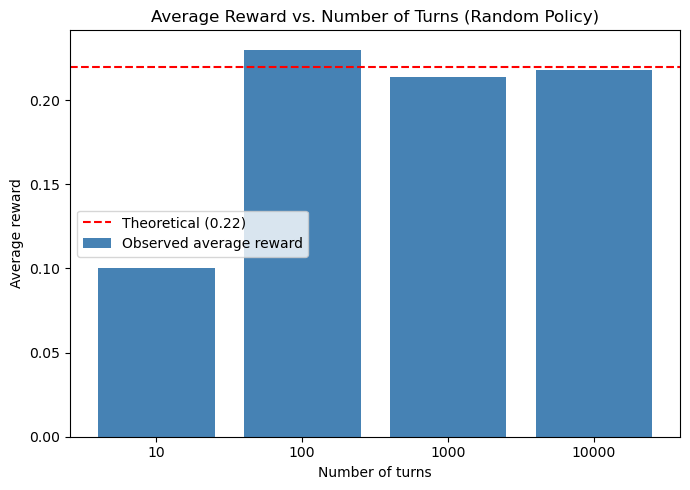

In [ ]:
A = [0, 1, 2, 3, 4]
turn_counts = [10, 100, 1000, 10000]
avg_rewards = []

for n in turn_counts:
    env = Contextual_Bandit_generator({'n_samples': 100000})
    rewards = []

    for _ in range(n):
        env.step()
        a = np.random.choice(A)   # purely random action, no learning
        env.reward(a)
        rewards.append(env.state['reward'][-1])

    avg_rewards.append(np.mean(rewards))
    print(f"turns={n}, average reward={np.mean(rewards):.4f}")

# theoretical expected reward under uniformly random action selection
theoretical = (1/5) * 0.9 + (4/5) * 0.05
print(f"theoretical average reward = {theoretical:.4f}")

# bar chart
plt.figure(figsize=(7, 5))
plt.bar([str(n) for n in turn_counts], avg_rewards, color='steelblue', label='Observed average reward')
plt.axhline(theoretical, color='red', linestyle='--', label=f'Theoretical ({theoretical:.2f})')
plt.xlabel('Number of turns')
plt.ylabel('Average reward')
plt.title('Average Reward vs. Number of Turns (Random Policy)')
plt.legend()
plt.tight_layout()
plt.savefig('section2_bar_chart.png')
plt.show()

# Question 7

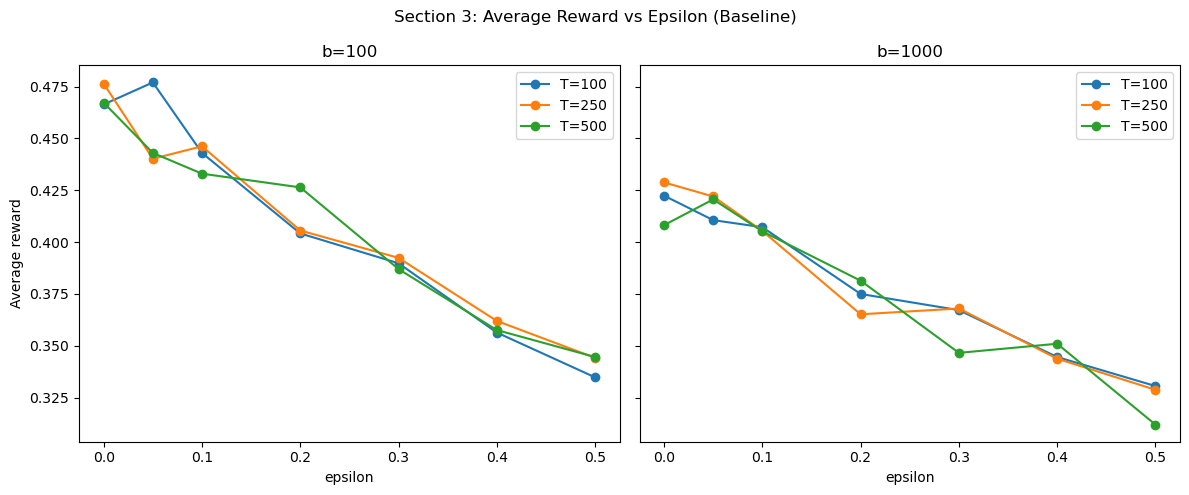

In [ ]:
# --- Baseline (Section 3) ---
baseline = [
    {'T':100,'b':100,'e':0,'avg':0.4664}, {'T':100,'b':100,'e':0.05,'avg':0.4770},
    {'T':100,'b':100,'e':0.1,'avg':0.4430}, {'T':100,'b':100,'e':0.2,'avg':0.4042},
    {'T':100,'b':100,'e':0.3,'avg':0.3898}, {'T':100,'b':100,'e':0.4,'avg':0.3564},
    {'T':100,'b':100,'e':0.5,'avg':0.3348}, {'T':100,'b':1000,'e':0,'avg':0.4224},
    {'T':100,'b':1000,'e':0.05,'avg':0.4106}, {'T':100,'b':1000,'e':0.1,'avg':0.4072},
    {'T':100,'b':1000,'e':0.2,'avg':0.3750}, {'T':100,'b':1000,'e':0.3,'avg':0.3672},
    {'T':100,'b':1000,'e':0.4,'avg':0.3446}, {'T':100,'b':1000,'e':0.5,'avg':0.3306},
    {'T':250,'b':100,'e':0,'avg':0.4764}, {'T':250,'b':100,'e':0.05,'avg':0.4402},
    {'T':250,'b':100,'e':0.1,'avg':0.4462}, {'T':250,'b':100,'e':0.2,'avg':0.4056},
    {'T':250,'b':100,'e':0.3,'avg':0.3924}, {'T':250,'b':100,'e':0.4,'avg':0.3620},
    {'T':250,'b':100,'e':0.5,'avg':0.3442}, {'T':250,'b':1000,'e':0,'avg':0.4288},
    {'T':250,'b':1000,'e':0.05,'avg':0.4220}, {'T':250,'b':1000,'e':0.1,'avg':0.4054},
    {'T':250,'b':1000,'e':0.2,'avg':0.3652}, {'T':250,'b':1000,'e':0.3,'avg':0.3680},
    {'T':250,'b':1000,'e':0.4,'avg':0.3438}, {'T':250,'b':1000,'e':0.5,'avg':0.3288},
    {'T':500,'b':100,'e':0,'avg':0.4672}, {'T':500,'b':100,'e':0.05,'avg':0.4430},
    {'T':500,'b':100,'e':0.1,'avg':0.4330}, {'T':500,'b':100,'e':0.2,'avg':0.4264},
    {'T':500,'b':100,'e':0.3,'avg':0.3870}, {'T':500,'b':100,'e':0.4,'avg':0.3576},
    {'T':500,'b':100,'e':0.5,'avg':0.3446}, {'T':500,'b':1000,'e':0,'avg':0.4082},
    {'T':500,'b':1000,'e':0.05,'avg':0.4206}, {'T':500,'b':1000,'e':0.1,'avg':0.4052},
    {'T':500,'b':1000,'e':0.2,'avg':0.3814}, {'T':500,'b':1000,'e':0.3,'avg':0.3466},
    {'T':500,'b':1000,'e':0.4,'avg':0.3510}, {'T':500,'b':1000,'e':0.5,'avg':0.3120},
]

df_base = pd.DataFrame(baseline).rename(columns={'avg': 'baseline'})

# Question 7
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, b_val in zip(axes, [100, 1000]):
    subset = df_base[df_base['b'] == b_val]
    for T_val in [100, 250, 500]:
        line = subset[subset['T'] == T_val].sort_values('e')
        ax.plot(line['e'], line['baseline'], marker='o', label=f'T={T_val}')
    ax.set_title(f'b={b_val}')
    ax.set_xlabel('epsilon')
    ax.legend()
axes[0].set_ylabel('Average reward')
fig.suptitle('Section 3: Average Reward vs Epsilon (Baseline)')
plt.tight_layout()
plt.show()